# Análisis exploratorio y visualización de las emisiones de CO₂ en Colombia

**Responsable:** Alexis   |  **Fuente de los datos:** Our World in Data

**Objetivo:** analizar cómo han cambiado las emisiones anuales de CO₂ en Colombia, en qué años fueron mayores y menores, y si muestran una tendencia de aumento o disminución.

> Este bloque va al final del notebook de Joel (`proyecto_co2.ipynb`). Aquí **no** se hace regresión lineal: eso corresponde a Yenifer.

**Cómo usarlo:** ejecuta las celdas de arriba hacia abajo. Los datos se toman, en este orden: (1) el DataFrame `colombia` de Joel si existe en el notebook; (2) el archivo `datos_limpios_colombia.csv` si lo subiste a Colab; (3) si no hay ninguno, se descargan de Our World in Data.

## Paso 1. Importar las herramientas de análisis

- `pandas` organiza y analiza los datos.
- `matplotlib` crea las gráficas.
- `numpy` hace cálculos numéricos.

También se definen los colores, el formato de números (1.234,5) y una función para guardar cada gráfica como imagen.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
from pathlib import Path
from IPython.display import display, Markdown

plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 200,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--',
    'axes.titlesize': 15,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
    'font.size': 11,
})

# Colores del informe
AZUL = '#1B6CA8'
NARANJA = '#E07B39'
ROJO = '#C0392B'
VERDE = '#2E8B57'
GRIS = '#6B7280'

CARPETA = Path('graficas')
CARPETA.mkdir(exist_ok=True)
FUENTE = 'Fuente: Our World in Data'


def fmt(valor, decimales=1):
    # Formato colombiano: punto para miles y coma para decimales (1.234,5)
    texto = f'{valor:,.{decimales}f}'
    return texto.replace(',', '@').replace('.', ',').replace('@', '.')


def eje_miles(eje, decimales=0):
    eje.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: fmt(v, decimales)))


def guardar(nombre):
    plt.savefig(CARPETA / f'{nombre}.png', bbox_inches='tight', facecolor='white')


print('Herramientas cargadas correctamente')

Herramientas cargadas correctamente


## Paso 2. Cargar y revisar la base de datos

Primero se busca el DataFrame `colombia` que dejó Joel. Luego se revisan las primeras filas, las columnas con sus tipos de datos y el resumen estadístico.

**Qué debes comprobar:** que aparezcan los años, las emisiones de CO₂ y que todos los registros sean de Colombia. Si algo está mal, avísale a Joel antes de continuar.

In [16]:
ARCHIVO = 'datos_limpios_colombia.csv'  # archivo limpio de Joel (si lo subes a Colab)

if 'colombia' in globals():
    print('Se usará el DataFrame colombia del notebook de Joel.')
    base = colombia.copy()
elif Path(ARCHIVO).exists():
    print('Se usará el archivo', ARCHIVO)
    base = pd.read_csv(ARCHIVO)
else:
    URL = 'https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv'
    todo = pd.read_csv(URL)
    base = todo[todo['country'] == 'Colombia'].copy()
    print('Datos descargados de Our World in Data (solo Colombia).')

print('Filas y columnas:', base.shape)

Datos descargados de Our World in Data (solo Colombia).
Filas y columnas: (276, 79)


In [17]:
print('PRIMEROS REGISTROS')
display(base.head())
print()
print('INFORMACIÓN GENERAL')
base.info()
print()
print('RESUMEN ESTADÍSTICO')
display(base.describe().T)

PRIMEROS REGISTROS


,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,...,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
10757,Colombia,1750,COL,1078643.0,NaN,0.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10758,Colombia,1751,COL,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10759,Colombia,1752,COL,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10760,Colombia,1753,COL,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10761,Colombia,1754,COL,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



INFORMACIÓN GENERAL
<class 'pandas.core.frame.DataFrame'>
Index: 276 entries, 10757 to 11032
Data columns (total 79 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   country                                    276 non-null    object 
 1   year                                       276 non-null    int64  
 2   iso_code                                   276 non-null    object 
 3   population                                 231 non-null    float64
 4   gdp                                        127 non-null    float64
 5   cement_co2                                 258 non-null    float64
 6   cement_co2_per_capita                      213 non-null    float64
 7   co2                                        170 non-null    float64
 8   co2_growth_abs                             169 non-null    float64
 9   co2_growth_prct                            169 non-null    float64
 10  co2_

,count,mean,std,min,25%,50%,75%,max
year,276.0,1.887500e+03,7.981854e+01,1.750000e+03,1.818750e+03,1.887500e+03,1.956250e+03,2.025000e+03
population,231.0,1.285820e+07,1.509232e+07,1.078643e+06,2.209466e+06,4.944811e+06,1.950121e+07,5.342563e+07
gdp,127.0,1.611136e+11,1.965352e+11,1.025100e+09,1.748768e+10,6.089101e+10,2.564769e+11,7.427170e+11
cement_co2,258.0,7.773566e-01,1.441402e+00,0.000000e+00,0.000000e+00,0.000000e+00,7.725000e-01,5.077000e+00
cement_co2_per_capita,213.0,2.790141e-02,3.823839e-02,0.000000e+00,0.000000e+00,0.000000e+00,6.600000e-02,1.120000e-01
...,...,...,...,...,...,...,...,...
temperature_change_from_n2o,174.0,3.448276e-05,1.829922e-04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e-03
total_ghg,175.0,1.760072e+02,1.068021e+02,2.639700e+01,7.970700e+01,1.687060e+02,2.358275e+02,4.777280e+02
total_ghg_excluding_lucf,175.0,3.218963e+01,4.207919e+01,5.790000e-01,1.140500e+00,7.117000e+00,5.822850e+01,1.419750e+02
trade_co2,35.0,9.571000e+00,6.789004e+00,-2.674000e+00,4.834500e+00,1.079300e+01,1.498150e+01,2.156900e+01


## Paso 3. Preparar los datos para las gráficas

Este código:
1. Busca solo las columnas del **año** y de las **emisiones de CO₂**, sin importar cómo se llamen exactamente.
2. Las convierte a números y elimina los registros incompletos.
3. Crea un DataFrame nuevo llamado `df`, **sin modificar** `colombia`, para no afectar el trabajo de Joel ni de Yenifer.
4. Deja las emisiones en **millones de toneladas (Mt)** para que las gráficas se lean mejor.

In [18]:
def normalizar(nombre):
    return str(nombre).strip().lower().replace('₂', '2').replace(' ', '_')


columnas = {normalizar(c): c for c in base.columns}

# Acepta los nombres del archivo de Joel (anio, emisiones_co2) y los originales de Our World in Data
col_anio = next((columnas[n] for n in ('year', 'anio', 'ano', 'año') if n in columnas), None)
col_emis = next((columnas[n] for n in ('emisiones_co2', 'co2', 'annual_co2_emissions', 'emisiones')
                 if n in columnas), None)
if col_emis is None:
    col_emis = next((orig for norm, orig in columnas.items()
                     if norm.startswith('annual_co2') and 'per_capita' not in norm), None)

if col_anio is None or col_emis is None:
    print('Columnas disponibles:', list(base.columns))
    raise ValueError('No se encontró la columna del año o de las emisiones. Avísale a Joel.')

print('Columna de año:', col_anio)
print('Columna de emisiones:', col_emis)

df = base[[col_anio, col_emis]].rename(columns={col_anio: 'Año', col_emis: 'Emisiones'})
df['Año'] = pd.to_numeric(df['Año'], errors='coerce')
df['Emisiones'] = pd.to_numeric(df['Emisiones'], errors='coerce')

antes = len(df)
df = df.dropna().sort_values('Año').reset_index(drop=True)
df['Año'] = df['Año'].astype(int)
print('Registros eliminados por datos incompletos:', antes - len(df))

Columna de año: year
Columna de emisiones: co2
Registros eliminados por datos incompletos: 106


In [19]:
# Unidad: se trabaja en millones de toneladas de CO₂ (Mt)
if df['Emisiones'].max() > 1_000_000:
    df['Emisiones'] = df['Emisiones'] / 1_000_000
    print('Los datos venían en toneladas: se convirtieron a millones de toneladas (Mt).')
else:
    print('Los datos ya están en millones de toneladas (Mt).')

UNIDAD = 'Emisiones de CO₂ (millones de toneladas, Mt)'

# Opcional: cambia None por un año (por ejemplo 1960) para analizar solo desde ese año
ANIO_DESDE = 1990
if ANIO_DESDE is not None:
    df = df[df['Año'] >= ANIO_DESDE].reset_index(drop=True)

faltantes = sorted(set(range(df['Año'].min(), df['Año'].max() + 1)) - set(df['Año']))
print('Años sin dato dentro del periodo:', faltantes if faltantes else 'ninguno')
print('Periodo:', df['Año'].min(), '-', df['Año'].max(), '| Registros:', len(df))
df.head()

Los datos ya están en millones de toneladas (Mt).
Años sin dato dentro del periodo: ninguno
Periodo: 1990 - 2025 | Registros: 36


,Año,Emisiones
0,1990,56.062
1,1991,55.862
2,1992,60.461
3,1993,62.374
4,1994,65.772


## Paso 4. Análisis estadístico

| Operación | Qué nos permite conocer |
|---|---|
| `len()` | Cantidad de registros |
| `mean()` | Promedio de emisiones |
| `median()` | Valor central de las emisiones |
| `std()` | Qué tanto varían los datos |
| `max()` / `min()` | Mayor y menor emisión registrada |

Además se identifican los años exactos con las mayores y menores emisiones.

In [20]:
em = df['Emisiones']
mayor = df.loc[em.idxmax()]
menor = df.loc[em.idxmin()]
anio_ini = int(df['Año'].min())
anio_fin = int(df['Año'].max())
anio_max = int(mayor['Año'])
anio_min = int(menor['Año'])
val_max = mayor['Emisiones']
val_min = menor['Emisiones']

resumen = pd.DataFrame({
    'Indicador': [
        'Periodo analizado',
        'Total de registros (años)',
        'Promedio',
        'Mediana',
        'Desviación estándar',
        'Emisión máxima',
        'Año de la emisión máxima',
        'Emisión mínima',
        'Año de la emisión mínima',
    ],
    'Valor': [
        f'{anio_ini} - {anio_fin}',
        str(len(df)),
        f'{fmt(em.mean(), 2)} Mt',
        f'{fmt(em.median(), 2)} Mt',
        f'{fmt(em.std(), 2)} Mt',
        f'{fmt(val_max, 2)} Mt',
        str(anio_max),
        f'{fmt(val_min, 2)} Mt',
        str(anio_min),
    ],
})

print('ANÁLISIS ESTADÍSTICO')
print(resumen.to_string(index=False))
print()
print('5 años con MAYORES emisiones')
print(df.nlargest(5, 'Emisiones')[['Año', 'Emisiones']].to_string(index=False))
print()
print('5 años con MENORES emisiones')
print(df.nsmallest(5, 'Emisiones')[['Año', 'Emisiones']].to_string(index=False))

ANÁLISIS ESTADÍSTICO
                Indicador       Valor
        Periodo analizado 1990 - 2025
Total de registros (años)          36
                 Promedio    75,60 Mt
                  Mediana    68,68 Mt
      Desviación estándar    16,99 Mt
           Emisión máxima   106,29 Mt
 Año de la emisión máxima        2024
           Emisión mínima    55,86 Mt
 Año de la emisión mínima        1991

5 años con MAYORES emisiones
 Año  Emisiones
2024    106.288
2023    105.349
2021    103.415
2019    101.932
2022    101.544

5 años con MENORES emisiones
 Año  Emisiones
1991     55.862
1990     56.062
2004     56.900
1999     57.975
2002     58.036


## Gráfica 1. Evolución histórica

Es la gráfica más importante. Muestra:
- La línea azul: las emisiones de cada año.
- La línea naranja punteada: el **promedio móvil de 10 años**, que suaviza los saltos y deja ver la tendencia general.
- La línea gris: el promedio de todo el periodo.
- Los puntos rojo y verde: los años de mayor y menor emisión.

**Qué debes analizar:** si las emisiones aumentaron o disminuyeron, si hubo periodos estables y si hubo subidas o caídas fuertes. Describe solo lo que ves en tu gráfica.

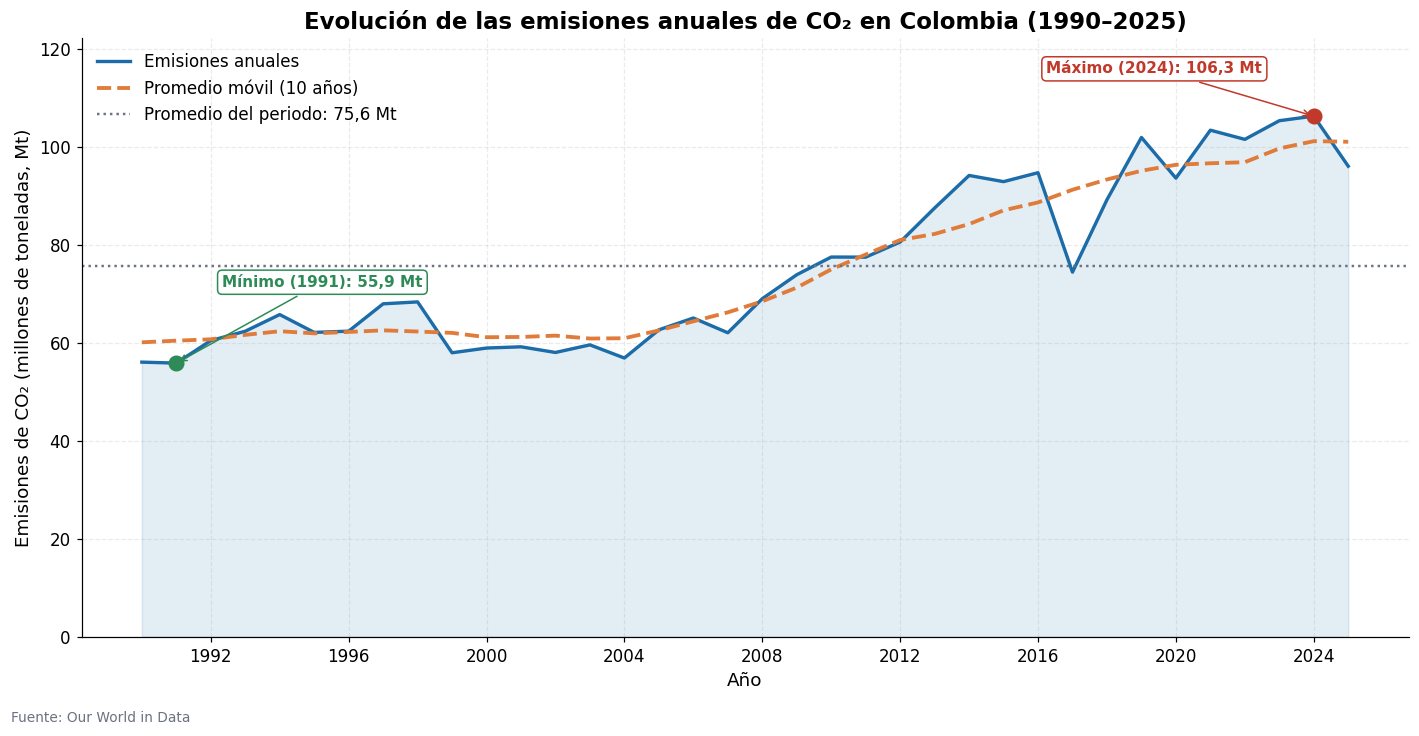

In [21]:
fig, ax = plt.subplots(figsize=(13, 6.5))

ax.plot(df['Año'], em, color=AZUL, linewidth=2.2, label='Emisiones anuales')
ax.fill_between(df['Año'], em, color=AZUL, alpha=0.12)

if len(df) >= 10:
    media_movil = em.rolling(10, center=True, min_periods=5).mean()
    ax.plot(df['Año'], media_movil, color=NARANJA, linewidth=2.5, linestyle='--',
            label='Promedio móvil (10 años)')

ax.axhline(em.mean(), color=GRIS, linestyle=':', linewidth=1.6,
           label=f'Promedio del periodo: {fmt(em.mean())} Mt')

mitad = (anio_ini + anio_fin) / 2
for anio, valor, color, texto, dy in [
    (anio_max, val_max, ROJO, 'Máximo', 28),
    (anio_min, val_min, VERDE, 'Mínimo', 50),
]:
    dx = -175 if anio > mitad else 30
    ax.scatter(anio, valor, color=color, s=90, zorder=5)
    ax.annotate(f'{texto} ({anio}): {fmt(valor)} Mt',
                xy=(anio, valor), xytext=(dx, dy), textcoords='offset points',
                fontsize=10, fontweight='bold', color=color,
                arrowprops=dict(arrowstyle='->', color=color),
                bbox=dict(boxstyle='round,pad=0.3', fc='white', ec=color))

ax.set_title(f'Evolución de las emisiones anuales de CO₂ en Colombia ({anio_ini}–{anio_fin})')
ax.set_xlabel('Año')
ax.set_ylabel(UNIDAD)
ax.set_ylim(0, em.max() * 1.15)
ax.xaxis.set_major_locator(mtick.MaxNLocator(integer=True, nbins=12))
eje_miles(ax)
ax.legend(loc='upper left', frameon=False)
fig.text(0.01, -0.02, FUENTE, fontsize=9, color=GRIS)
plt.tight_layout()
guardar('grafica_1_evolucion')
plt.show()

## Gráfica 2. Comparación de los últimos 15 años

Permite ver con más claridad los cambios recientes. Cada barra es un año y su valor aparece encima. La barra **roja** es el año de mayor emisión de ese periodo y la **verde** el de menor emisión.

**Qué debes observar:** compara las alturas de las barras y di qué años tuvieron más o menos emisiones dentro de ese periodo.

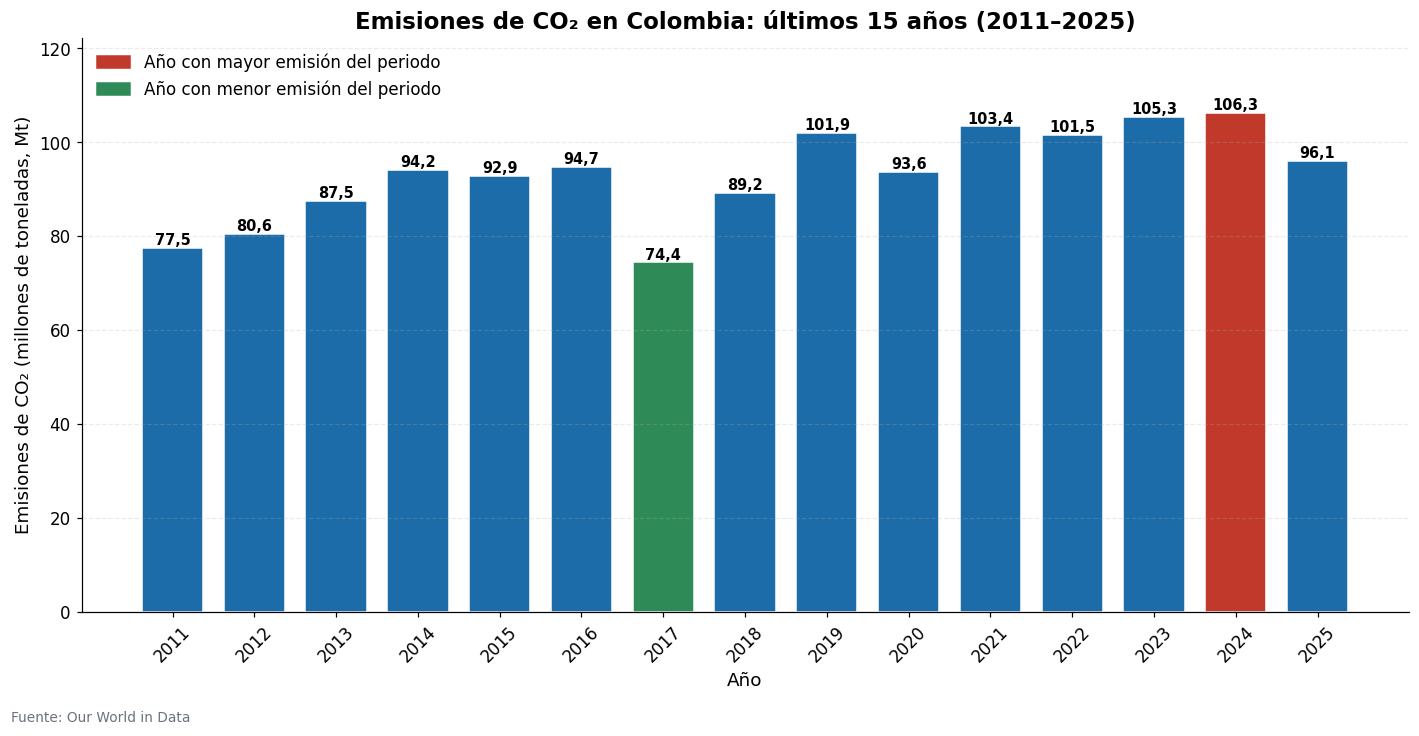

In [22]:
ultimos = df.tail(15).reset_index(drop=True)
valores = ultimos['Emisiones']
a_ini = int(ultimos['Año'].iloc[0])
a_fin = int(ultimos['Año'].iloc[-1])

colores = [AZUL] * len(ultimos)
colores[int(valores.idxmax())] = ROJO
colores[int(valores.idxmin())] = VERDE

fig, ax = plt.subplots(figsize=(13, 6.5))
barras = ax.bar(ultimos['Año'].astype(str), valores, color=colores, edgecolor='white', width=0.75)

for barra, valor in zip(barras, valores):
    ax.text(barra.get_x() + barra.get_width() / 2, valor, fmt(valor),
            ha='center', va='bottom', fontsize=9.5, fontweight='bold')

ax.set_ylim(0, valores.max() * 1.15)
ax.set_title(f'Emisiones de CO₂ en Colombia: últimos {len(ultimos)} años ({a_ini}–{a_fin})')
ax.set_xlabel('Año')
ax.set_ylabel(UNIDAD)
ax.grid(axis='x', visible=False)
eje_miles(ax)
plt.setp(ax.get_xticklabels(), rotation=45)
ax.legend(handles=[Patch(color=ROJO, label='Año con mayor emisión del periodo'),
                   Patch(color=VERDE, label='Año con menor emisión del periodo')],
          loc='upper left', frameon=False)
fig.text(0.01, -0.02, FUENTE, fontsize=9, color=GRIS)
plt.tight_layout()
guardar('grafica_2_ultimos_15_anios')
plt.show()

## Gráfica 3. Distribución de las emisiones

- El eje horizontal muestra los niveles de emisiones.
- El eje vertical muestra **cuántos años** caen en cada intervalo.
- La línea roja es el promedio y la verde es la mediana.

Si el promedio es mayor que la mediana, algunos años con emisiones altas están subiendo el promedio. Identifica si los valores se concentran en ciertos intervalos o si están muy repartidos.

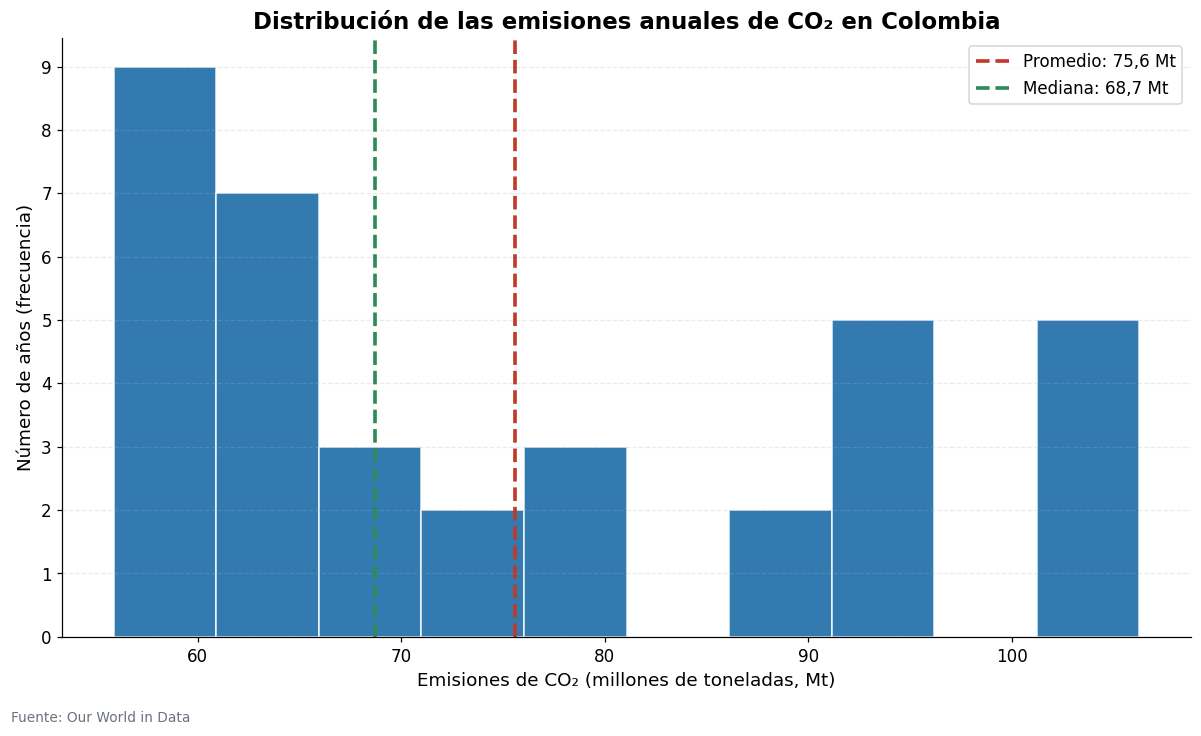

El intervalo más frecuente va de 55,9 a 60,9 Mt, con 9 años.


In [23]:
BINS = 10  # número de intervalos del histograma (con pocos años, 8 a 10 se lee mejor)

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.hist(em, bins=BINS, color=AZUL, edgecolor='white', alpha=0.9)
ax.axvline(em.mean(), color=ROJO, linestyle='--', linewidth=2.4,
           label=f'Promedio: {fmt(em.mean())} Mt')
ax.axvline(em.median(), color=VERDE, linestyle='--', linewidth=2.4,
           label=f'Mediana: {fmt(em.median())} Mt')

ax.set_title('Distribución de las emisiones anuales de CO₂ en Colombia')
ax.set_xlabel(UNIDAD)
ax.set_ylabel('Número de años (frecuencia)')
ax.yaxis.set_major_locator(mtick.MaxNLocator(integer=True))
ax.grid(axis='x', visible=False)
ax.legend(frameon=True, fontsize=11)
fig.text(0.01, -0.02, FUENTE, fontsize=9, color=GRIS)
plt.tight_layout()
guardar('grafica_3_histograma')
plt.show()

conteos, bordes = np.histogram(em, bins=BINS)
i = int(conteos.argmax())
print(f'El intervalo más frecuente va de {fmt(bordes[i])} a {fmt(bordes[i + 1])} Mt, con {int(conteos[i])} años.')

##Gráficas complementarias
### Gráfica 4. Variación anual (%)
Muestra cuánto subieron (rojo) o bajaron (verde) las emisiones respecto al año anterior. Sirve para identificar **aumentos o disminuciones importantes**. Se usan los últimos 40 años porque, en los primeros años, los valores son tan pequeños que los porcentajes se disparan y dañan la gráfica.

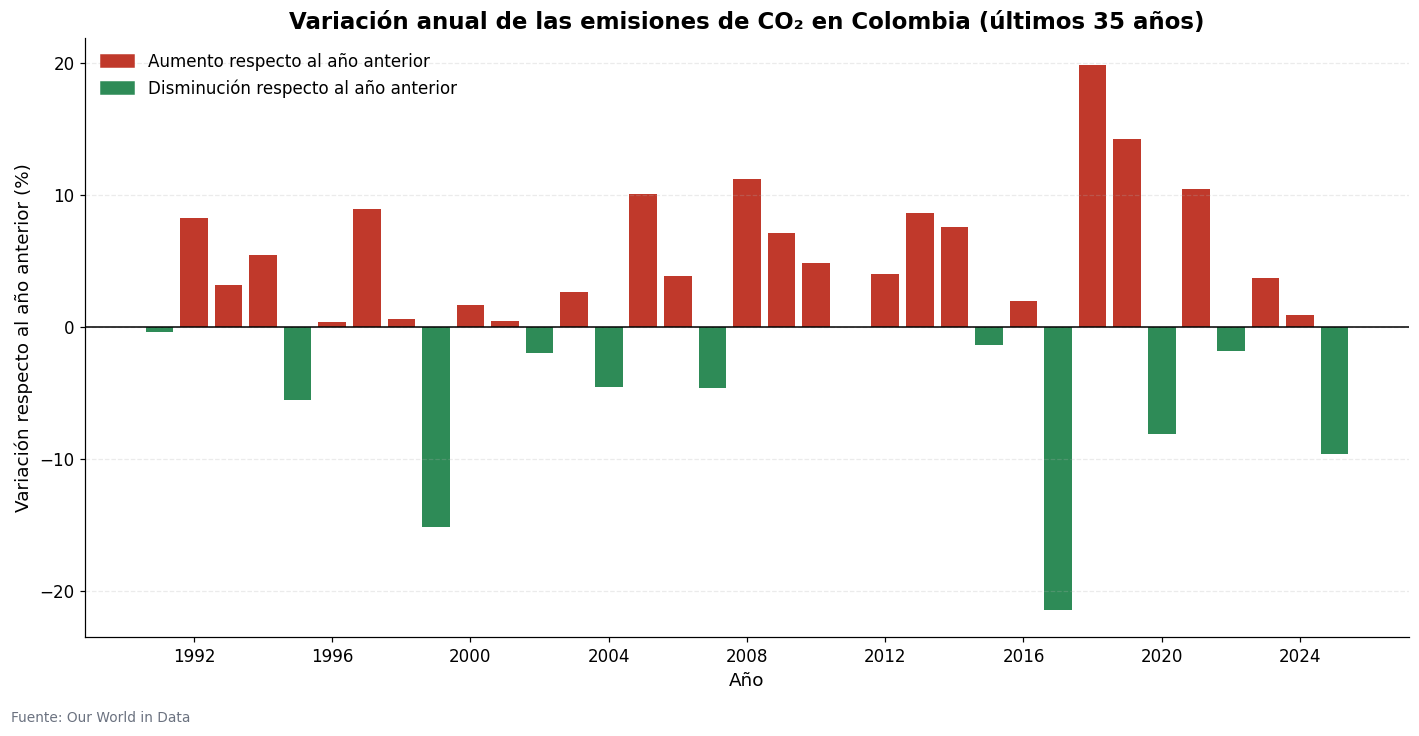

Mayor aumento anual: 2018 (19,9 %)
Mayor disminución anual: 2017 (-21,4 %)


In [24]:
df['Variación anual (%)'] = em.pct_change().replace([np.inf, -np.inf], np.nan) * 100

VENTANA = 40
var = df.tail(VENTANA).dropna(subset=['Variación anual (%)'])
colores = [ROJO if v > 0 else VERDE for v in var['Variación anual (%)']]

fig, ax = plt.subplots(figsize=(13, 6.5))
ax.bar(var['Año'], var['Variación anual (%)'], color=colores, width=0.8)
ax.axhline(0, color='black', linewidth=1)

ax.set_title(f'Variación anual de las emisiones de CO₂ en Colombia (últimos {len(var)} años)')
ax.set_xlabel('Año')
ax.set_ylabel('Variación respecto al año anterior (%)')
ax.xaxis.set_major_locator(mtick.MaxNLocator(integer=True, nbins=12))
ax.grid(axis='x', visible=False)
ax.legend(handles=[Patch(color=ROJO, label='Aumento respecto al año anterior'),
                   Patch(color=VERDE, label='Disminución respecto al año anterior')],
          loc='upper left', frameon=False)
fig.text(0.01, -0.02, FUENTE, fontsize=9, color=GRIS)
plt.tight_layout()
guardar('grafica_4_variacion_anual')
plt.show()

fila_alza = var.loc[var['Variación anual (%)'].idxmax()]
fila_baja = var.loc[var['Variación anual (%)'].idxmin()]
anio_alza = int(fila_alza['Año'])
anio_baja = int(fila_baja['Año'])
var_alza = fila_alza['Variación anual (%)']
var_baja = fila_baja['Variación anual (%)']
print(f'Mayor aumento anual: {anio_alza} ({fmt(var_alza, 1)} %)')
print(f'Mayor disminución anual: {anio_baja} ({fmt(var_baja, 1)} %)')

### Gráfica 5. Promedio de emisiones por década
Resume la historia en pocas barras. Debajo de cada década aparece cuántos años tienen dato: una década con pocos años (la primera o la última) no es totalmente comparable con las demás.

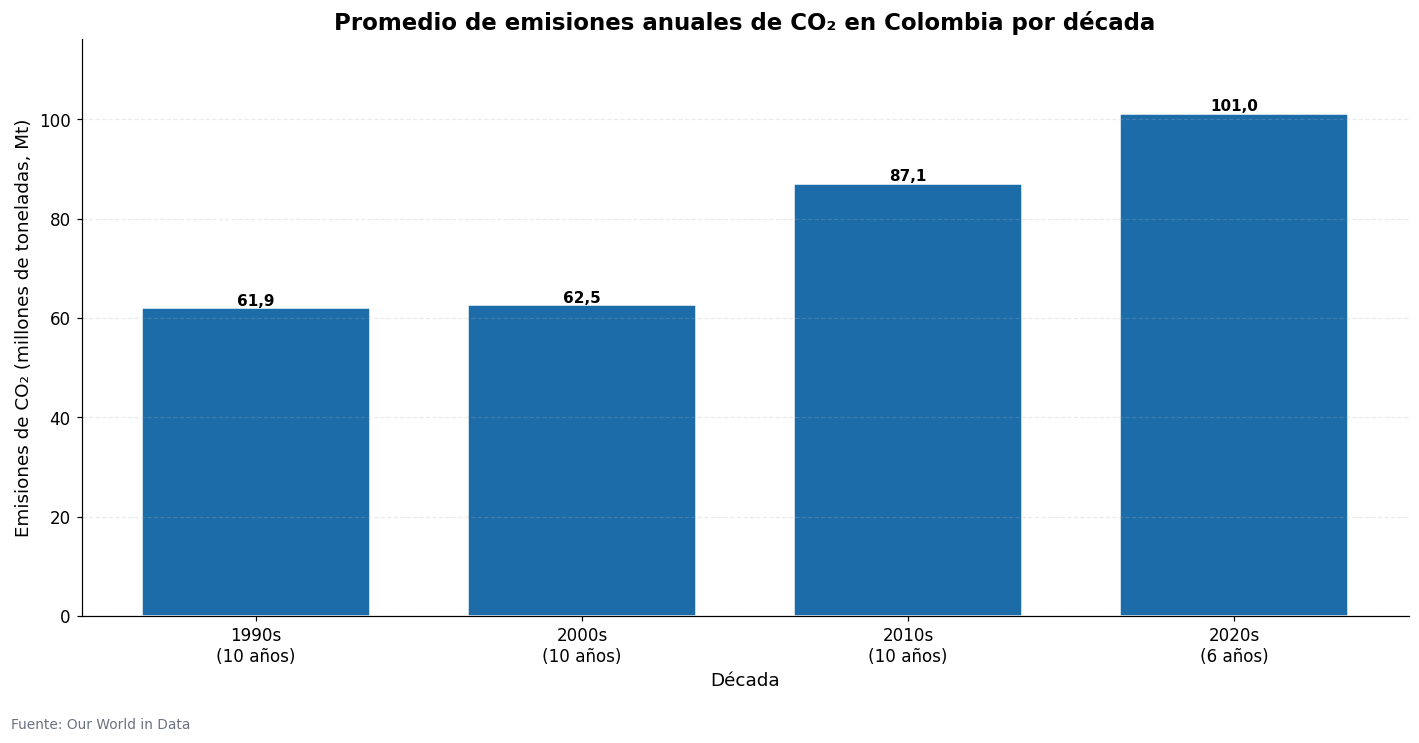

In [25]:
df['Década'] = (df['Año'] // 10) * 10
decadas = df.groupby('Década')['Emisiones'].agg(['mean', 'count']).reset_index().tail(14)
etiquetas = [f'{int(d)}s' + chr(10) + f'({int(n)} años)'
             for d, n in zip(decadas['Década'], decadas['count'])]

fig, ax = plt.subplots(figsize=(13, 6.5))
barras = ax.bar(etiquetas, decadas['mean'], color=AZUL, edgecolor='white', width=0.7)
for barra, valor in zip(barras, decadas['mean']):
    ax.text(barra.get_x() + barra.get_width() / 2, valor, fmt(valor),
            ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylim(0, decadas['mean'].max() * 1.15)
ax.set_title('Promedio de emisiones anuales de CO₂ en Colombia por década')
ax.set_xlabel('Década')
ax.set_ylabel(UNIDAD)
ax.grid(axis='x', visible=False)
eje_miles(ax)
fig.text(0.01, -0.03, FUENTE, fontsize=9, color=GRIS)
plt.tight_layout()
guardar('grafica_5_por_decada')
plt.show()

## Paso 8. Cambio entre el primer y el último año

Si el cambio porcentual es **positivo**, hubo un aumento; si es **negativo**, una disminución.

Ojo: si el primer año tiene un valor muy pequeño, el porcentaje total sale enorme y engañoso. Por eso también se calcula el cambio en los últimos 10 y 20 años, y el crecimiento promedio anual.

In [26]:
def cambio_pct(inicial, final):
    if inicial == 0:
        return np.nan
    return (final - inicial) / inicial * 100


primero = df.iloc[0]
ultimo = df.iloc[-1]
inicial = primero['Emisiones']
final = ultimo['Emisiones']
cambio = cambio_pct(inicial, final)
n_anios = int(ultimo['Año'] - primero['Año'])

print('CAMBIO ENTRE EL PRIMER Y EL ÚLTIMO AÑO')
print('Primer año:', anio_ini)
print('Último año:', anio_fin)
print('Emisiones iniciales:', fmt(inicial, 2), 'Mt')
print('Emisiones finales:', fmt(final, 2), 'Mt')

if np.isnan(cambio):
    print('No se puede calcular el cambio porcentual porque el valor inicial es cero.')
else:
    print('Cambio porcentual:', fmt(cambio, 2), '%')
    print('Resultado:', 'AUMENTO' if cambio > 0 else 'DISMINUCIÓN')

if inicial > 0 and n_anios > 0:
    tcac = ((final / inicial) ** (1 / n_anios) - 1) * 100
    print('Crecimiento promedio anual (compuesto):', fmt(tcac, 2), '% por año')


def cambio_ultimos(n):
    if len(df) <= n:
        return None, np.nan
    fila = df.iloc[-(n + 1)]
    return int(fila['Año']), cambio_pct(fila['Emisiones'], final)


anio_b10, cambio_10 = cambio_ultimos(10)
anio_b20, cambio_20 = cambio_ultimos(20)

print()
print('CAMBIO EN PERIODOS RECIENTES')
for n, a, c in [(10, anio_b10, cambio_10), (20, anio_b20, cambio_20)]:
    if a is not None:
        print(f'Últimos {n} años ({a} a {anio_fin}): {fmt(c, 2)} %')

CAMBIO ENTRE EL PRIMER Y EL ÚLTIMO AÑO
Primer año: 1990
Último año: 2025
Emisiones iniciales: 56,06 Mt
Emisiones finales: 96,07 Mt
Cambio porcentual: 71,36 %
Resultado: AUMENTO
Crecimiento promedio anual (compuesto): 1,55 % por año

CAMBIO EN PERIODOS RECIENTES
Últimos 10 años (2015 a 2025): 3,40 %
Últimos 20 años (2005 a 2025): 53,31 %


## Interpretación de los resultados

Para este trabajo analizamos las emisiones de CO₂ en Colombia durante el periodo comprendido entre 1990 y 2025, utilizando un total de 36 registros.

Al revisar la gráfica de evolución histórica, pudimos observar que las emisiones han aumentado en general con el paso de los años. En 1990 se registraban aproximadamente 56,1 millones de toneladas, mientras que en 2025 llegaron a 96,1 millones de toneladas.

También encontramos que el año con menores emisiones fue 1991, con 55,9 millones de toneladas, y el año con mayores emisiones fue 2024, cuando se alcanzaron 106,3 millones de toneladas.

En el análisis estadístico obtuvimos un promedio de 75,6 millones de toneladas y una mediana de 68,7 millones. Estos resultados nos ayudan a tener una idea más clara de los niveles de emisiones que presentó Colombia durante el periodo estudiado.

Por medio de la gráfica de los últimos 15 años pudimos comparar mejor los cambios recientes. Allí se observa que las emisiones alcanzaron valores elevados entre 2019 y 2024. También llama la atención el descenso que ocurrió en 2017 y el aumento que se presentó nuevamente en 2018.

Al comparar las emisiones por décadas, encontramos que el promedio fue aumentando: pasó de 61,9 millones de toneladas en los años noventa a 62,5 millones en los años 2000. Luego aumentó a 87,1 millones en los años 2010 y llegó a 101,0 millones en los años 2020. Este último resultado corresponde a los seis años comprendidos entre 2020 y 2025.

Por último, el histograma nos permitió observar cómo se distribuyen las emisiones durante los años analizados y comparar sus valores con el promedio y la mediana.

En general, las gráficas nos ayudaron a comprender mejor cómo han cambiado las emisiones de CO₂ en Colombia y a identificar los años y periodos en los que se presentaron las variaciones más importantes.


## Conclusiones

1. Con este análisis pudimos identificar que las emisiones de CO₂ en Colombia han aumentado en términos generales. Al comparar 1990 con 2025, encontramos que pasaron de 56,1 a 96,1 millones de toneladas, lo que representa un incremento aproximado del 71,4 %.

2. También encontramos diferencias importantes entre los años estudiados. El valor más alto se presentó en 2024, con 106,3 millones de toneladas, mientras que el más bajo fue en 1991, con 55,9 millones de toneladas.

3. Al comparar los resultados por décadas, observamos que los promedios de emisiones fueron mayores durante los años 2010 y 2020 que en las dos décadas anteriores.

4. Las gráficas también nos permitieron reconocer que las emisiones no aumentaron de manera constante, ya que hubo años en los que disminuyeron y otros en los que volvieron a subir.

5. Esta actividad nos permitió poner en práctica herramientas de Python, como Pandas y Matplotlib, para organizar información, realizar cálculos estadísticos y representar los resultados mediante gráficas.

6. Finalmente, este análisis nos permitió conocer mejor el comportamiento de las emisiones de CO₂ en Colombia y nos deja una base para continuar con la siguiente parte del proyecto, que consiste en aplicar un modelo de regresión lineal para estudiar su tendencia.